In [1]:
import sys
import os
import numpy as np
import pandas as pd

from sklearn.decomposition import PCA


sys.path.append(os.path.join(os.getcwd(), '../../src'))
from utils_robot import generate_utils
from utils_robot import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from models import hgm
from models import bom

In [2]:
import importlib
importlib.reload(generate_utils)
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(bom)
importlib.reload(hgm)

<module 'models.hgm' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/models/hgm.py'>

In [3]:
file_ids = list(range(0, 33+1))
# file_ids = [0,   # minrevs
# 			1,   # minswitch
# 			7,   # maxswitch
# 			11,  # median
# 			12,  # maxrevs
# 			17,  # mean
# 			19,  # paper
# 			21]  # clean
# file_ids = [19]
plot_id = 19

weights = (0.1, -0.25)
n_neurons = 6
# states = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']
states = ['REV', 'VENTRAL_TURN']

dims = 2

In [4]:
# read
path = os.path.join(read_utils.get_data_path(), 'exported_data_gcamp')
(template_ids, filenames_gcamp,
 discrete_states, eigenworms) = read_utils.get_datas(path, file_ids)

for i in range(len(file_ids)):
	# clear nan values
	mask = eigenworms[i].notna().all(axis=1)

	eigenworms[i] = eigenworms[i][mask]
	discrete_states[i] = discrete_states[i][mask]

# preprocess
pass

In [5]:
# generate
file_ids = template_ids.copy()
filenames = list()
modes = list()
traces_reconstructed = list()
traces_residual = list()
traces = list()
params = list()
params_cca = list()

for file_id in file_ids:
	(filename,
	 modes_,
	 traces_reconstructed_,
	 traces_residual_,
	 traces_,
	 params_,
	 params_cca_) = generate_utils.artificialize(weights, hgm,
												filenames_gcamp[file_ids.index(file_id)],
												[f'N{i}' for i in range(n_neurons)],
												eigenworms[file_ids.index(file_id)],
												discrete_states[file_ids.index(file_id)][states],
												n_dimensions=len(states))

	filenames.append(filename)
	modes.append(modes_)
	traces_reconstructed.append(traces_reconstructed_)
	traces_residual.append(traces_residual_)
	traces.append(traces_)
	params.append(params_)
	params_cca.append(params_cca_)

In [6]:
neurons = [f'N{i}' for i in range(n_neurons)]

plot_idx = file_ids.index(plot_id)

# discrete_states = [ds[selection_bhl] for ds in discrete_states]

In [7]:
(modes_manifold,
 recos_manifold,
 loads_pca_man,
 vars_expl_mans) = train_utils.get_manifolds_pca(traces, zscore=False,
												 n_pc=dims)

In [8]:
save = False

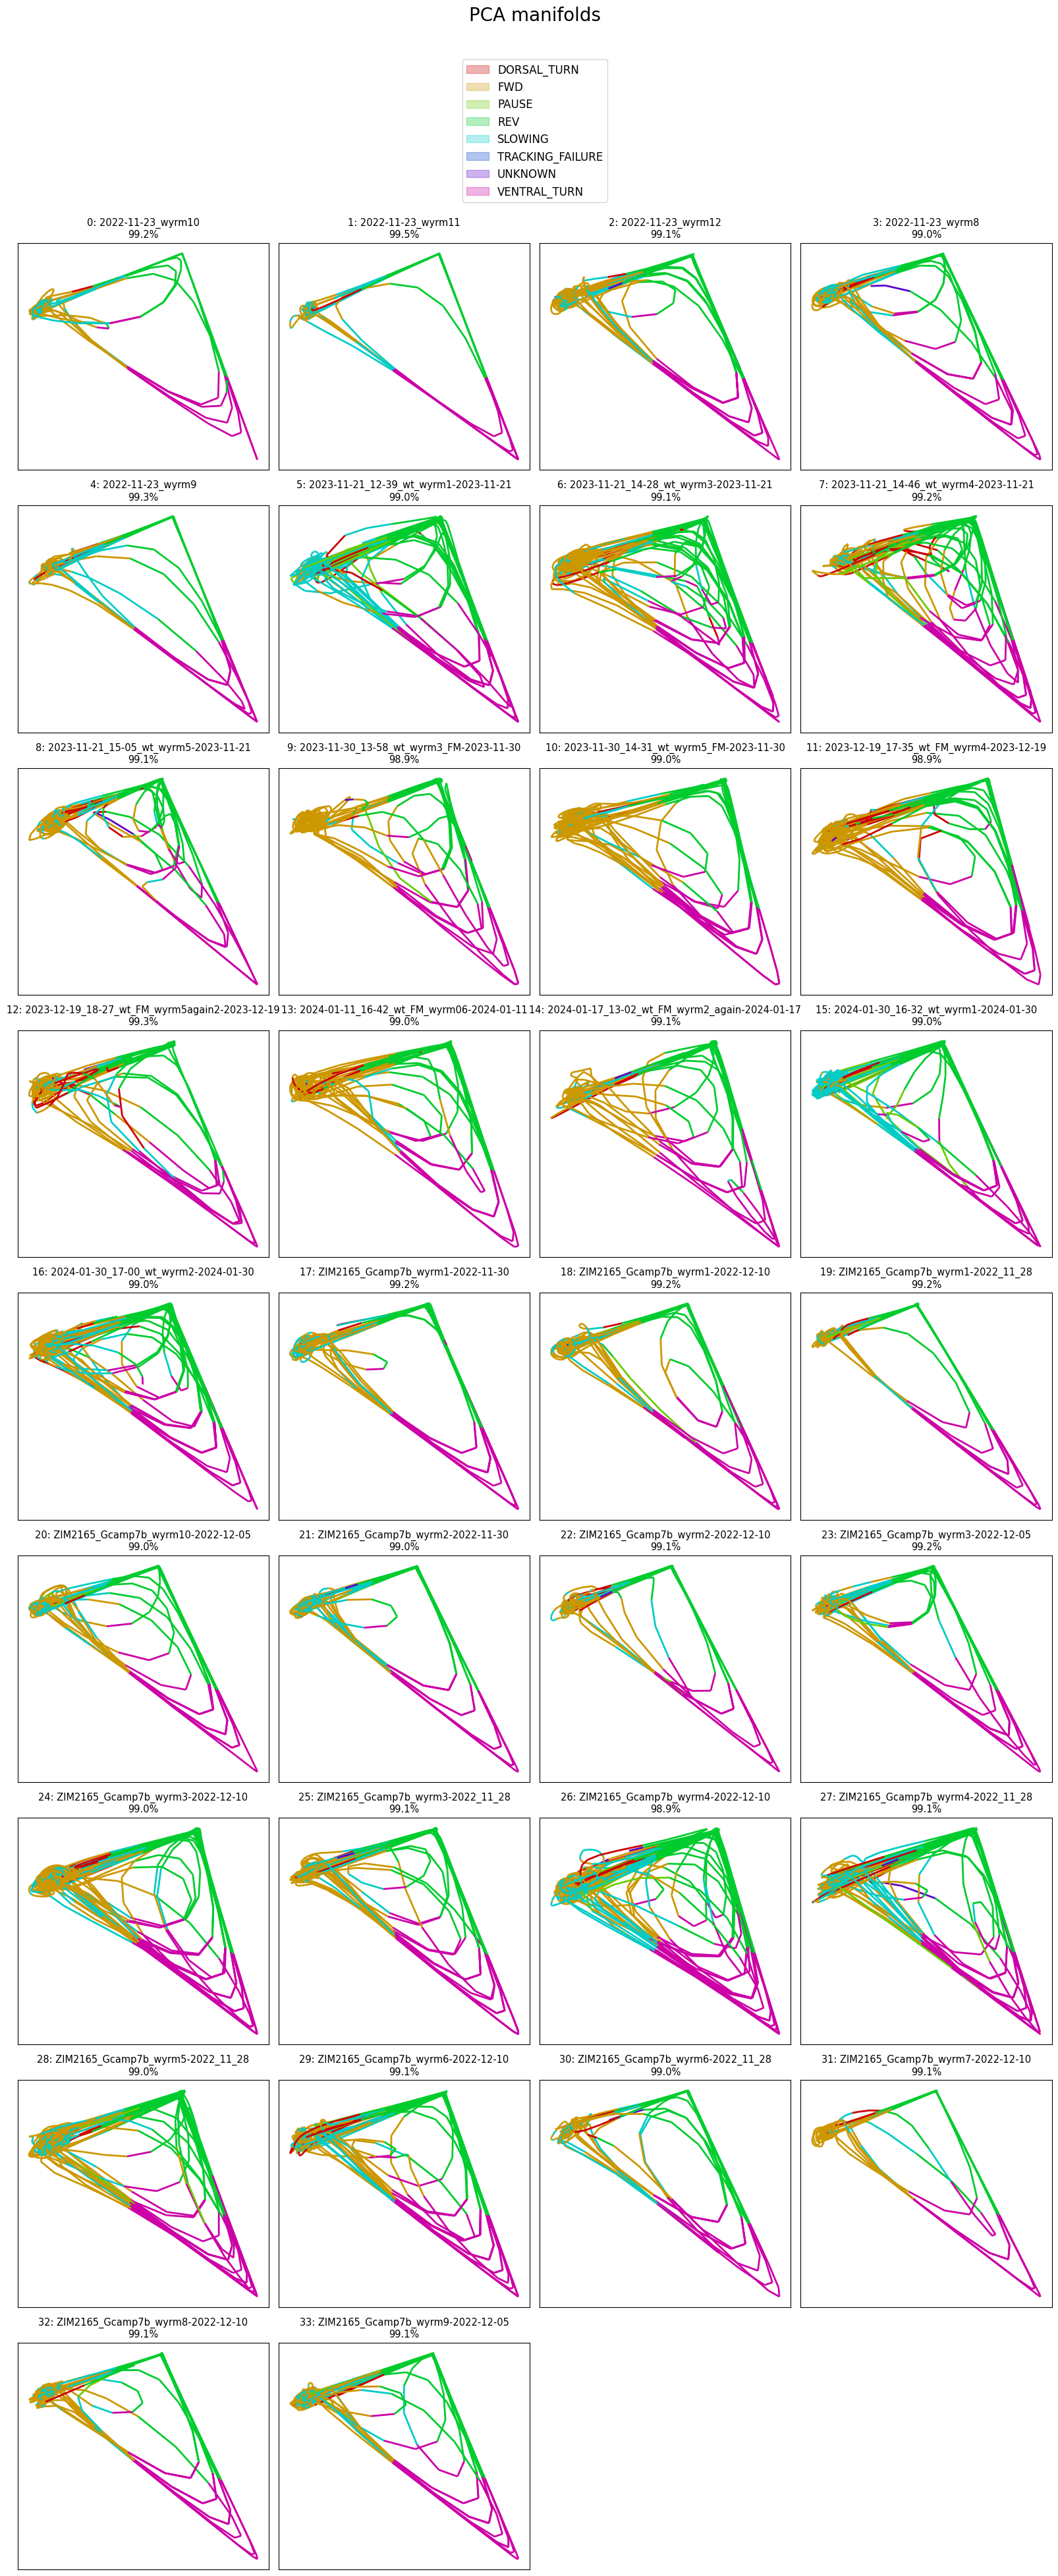

99.1%


In [9]:
plot_utils.plot_manifolds([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
						  modes_manifold,
						  discrete_states,
						  [vx[:2] for vx in vars_expl_mans], None,
						  title='PCA manifolds', top_space=3.5,
						  save_path=f'../../out/plots/manifolds/{dims}-dim-PCA' if save else None)

In [10]:
# plot_utils.plot_manifolds_3d([f'{str(file_id)}: {filenames[plot_idx]}' for file_id in file_ids],
# 							 modes_manifold, discrete_states,
# 							 [vx[:3] for vx in vars_expl_mans], None,
# 							 title='PCA manifolds', top_space=3.5,
# 							 save_path=f'../../out/plots/manifolds/{dims}-dim-PCA_3d' if save else None)

In [11]:
# plot_utils.plot_manifolds_3d_sep([f'{str(file_id)}: {filenames[plot_idx]}' for file_id in file_ids],
# 								 modes_manifold, discrete_states,
# 								 [vx[:3] for vx in vars_expl_mans], None,
# 								 titles=['PCA manifolds'] * len(file_ids), top_space=3.5, animate=True,
# 								 save_path=f'../../out/plots/manifolds/{dims}-dim-PCA_3d' if save else None)

In [12]:
for i, trace in enumerate(traces):
	print(np.mean(trace.values, axis=0))

[-0.0092797  -0.00398546 -0.00948062 -0.00517754 -0.00858659 -0.00203659]
[-0.02792149 -0.02498543 -0.01547278 -0.03606183 -0.00441416 -0.01414145]
[ 0.00610468 -0.00651898 -0.00095908 -0.00733837  0.00812117  0.00181401]
[-0.00050258 -0.00738446 -0.00760089 -0.01208575  0.01088547  0.00135958]
[-0.01628485 -0.01764981 -0.01014188 -0.02399819 -0.00184885 -0.00788095]
[-0.00659317 -0.00602189 -0.00649417 -0.00985271  0.00066839 -0.00219554]
[-0.00338671  0.00420566  0.00470714  0.00315404 -0.01723231 -0.00876458]
[-0.03972069 -0.02945337  0.0063549  -0.0457335   0.00024487 -0.02977975]
[-0.01299312 -0.01378309 -0.00740743 -0.02497984  0.01321174 -0.0062293 ]
[ 0.0166765  -0.0008982   0.00435607 -0.0050771   0.00968194 -0.0004048 ]
[ 0.00429164 -0.01739551 -0.01547652 -0.0343064   0.02593947 -0.00066943]
[-0.00593183 -0.01509792 -0.01852918 -0.02665704 -0.00229749 -0.00732671]
[-0.01106598 -0.00093319 -0.01389016 -0.00278599 -0.01150835 -0.00073283]
[-6.6219116e-05 -1.5213746e-02 -1.0361

In [13]:
traces_residual = [pd.DataFrame(t.values - t_rec.values, columns=t.columns) for t, t_rec in zip(traces, recos_manifold)]

for i, trace in enumerate(traces_residual):
	print(np.mean(trace.values, axis=0))

[ 1.2585984e-08  2.4027788e-08 -7.1511272e-09 -5.7209015e-09
 -3.5755636e-09 -6.2929919e-09]
[-1.43022545e-08 -2.28836061e-08 -2.00231565e-09 -2.00231565e-09
  1.51603903e-08 -2.86045077e-10]
[ 1.0876238e-08 -2.6331945e-08  3.4346013e-09  3.7208181e-09
  1.6028141e-08  6.8692025e-09]
[ 9.1534424e-09 -1.9451067e-08  6.8650823e-09 -1.2442961e-08
 -2.2883606e-08 -1.8592931e-09]
[ 9.7255333e-09 -8.5813525e-09  2.2883606e-08  1.2872029e-08
  8.0092626e-09 -1.5875502e-08]
[-2.4555685e-08  3.7690121e-08 -1.0279124e-08  3.4263747e-09
 -1.3705499e-08 -1.7131874e-09]
[-5.8533902e-09 -2.1700373e-08 -7.4238122e-09  8.5659373e-09
 -1.9987185e-09 -3.1051521e-09]
[ 4.6256059e-08 -5.8248371e-08 -5.7106249e-09 -4.5684998e-09
  2.2842499e-08  6.4244525e-09]
[ 1.8559531e-08 -2.8267593e-08  8.5659368e-10 -2.8553124e-10
  2.2842499e-09  8.5659368e-10]
[ 1.8890308e-08 -4.9801720e-08 -9.4451540e-09  1.4954827e-08
  2.9337221e-08 -3.1483847e-09]
[ 3.7494399e-08 -7.4416362e-09  2.8621677e-10 -1.7173006e-09
  1